# 四层探测器 PoCA 重建
读取 Geant4 生成的四层击中位置、拟合结果和 PoCA 散射位置。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("muon_tracks.csv")
print(df.head())
print("complete tracks:", len(df))


   event  up1_x_mm  up1_y_mm  up1_z_mm  up2_x_mm  up2_y_mm  up2_z_mm  \
0      0 -110.8530   35.3250      -405 -110.8890   35.2894      -305   
1      1  139.8240  111.5770      -405  139.8520  111.5270      -305   
2      2  -15.3030   47.0570      -405  -15.2627   47.0420      -305   
3      3  147.7620   75.6027      -405  147.7570   75.5786      -305   
4      4  -64.9429   48.3917      -405  -64.9405   48.3913      -305   

   down1_x_mm  down1_y_mm  down1_z_mm  down2_x_mm  down2_y_mm  down2_z_mm  \
0   -111.0080     35.1196         295   -111.0400     35.1194         395   
1    139.8900    111.3610         295    139.9050    111.3270         395   
2    -15.1732     46.2895         295    -15.2252     46.0542         395   
3    147.8980     75.9340         295    147.9160     76.0192         395   
4    -64.9563     48.0537         295    -64.9562     48.0270         395   

   poca_x_mm  poca_y_mm  poca_z_mm  theta_x_mrad  theta_y_mrad  theta_mrad  
0  -111.0050    35.1248   1

## 1. 四层击中位置
上游两层用于拟合入射径迹，下游两层用于拟合出射径迹。

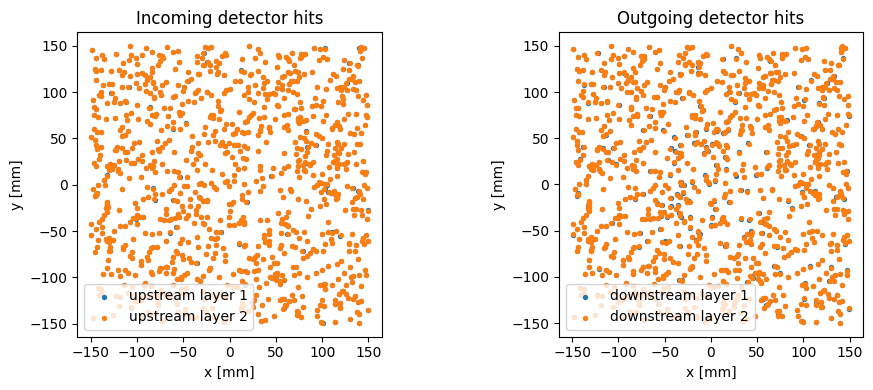

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(df["up1_x_mm"], df["up1_y_mm"], s=8, label="upstream layer 1")
axes[0].scatter(df["up2_x_mm"], df["up2_y_mm"], s=8, label="upstream layer 2")
axes[0].set_title("Incoming detector hits")
axes[0].set_xlabel("x [mm]"); axes[0].set_ylabel("y [mm]")
axes[0].set_aspect("equal"); axes[0].legend()
axes[1].scatter(df["down1_x_mm"], df["down1_y_mm"], s=8, label="downstream layer 1")
axes[1].scatter(df["down2_x_mm"], df["down2_y_mm"], s=8, label="downstream layer 2")
axes[1].set_title("Outgoing detector hits")
axes[1].set_xlabel("x [mm]"); axes[1].set_ylabel("y [mm]")
axes[1].set_aspect("equal"); axes[1].legend()
plt.tight_layout()


## 2. 散射角分布
散射角由入射和出射径迹方向之差得到。

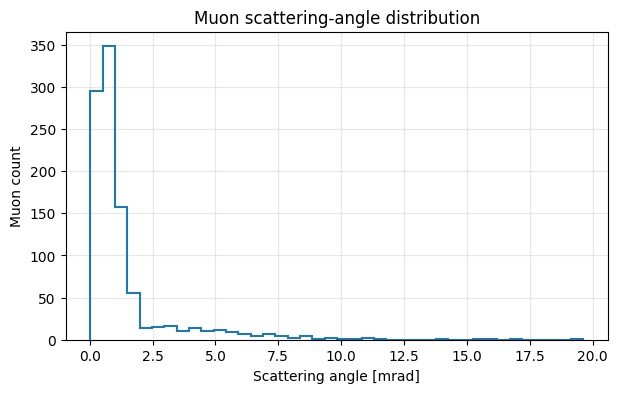

In [3]:
plt.figure(figsize=(7, 4))
plt.hist(df["theta_mrad"], bins=40, histtype="step", linewidth=1.5)
plt.xlabel("Scattering angle [mrad]"); plt.ylabel("Muon count")
plt.title("Muon scattering-angle distribution")
plt.grid(alpha=0.3); plt.show()


## 3. PoCA 三维散射点
PoCA 点是入射和出射拟合直线最近点连线的中点。颜色表示散射角大小。

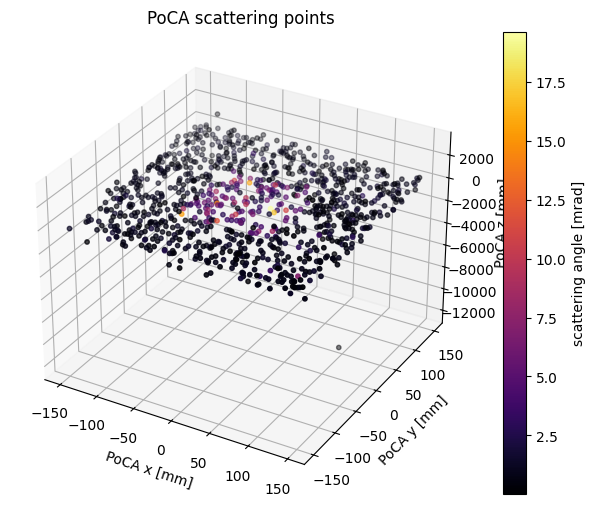

In [4]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(df["poca_x_mm"], df["poca_y_mm"], df["poca_z_mm"], c=df["theta_mrad"], s=10, cmap="inferno")
ax.set_xlabel("PoCA x [mm]"); ax.set_ylabel("PoCA y [mm]"); ax.set_zlabel("PoCA z [mm]")
ax.set_title("PoCA scattering points")
fig.colorbar(sc, ax=ax, label="scattering angle [mrad]")
plt.show()


## 4. XY 平面 PoCA 投影
这是最基础的二维散射成像结果。后续可以改为三维体素累积。

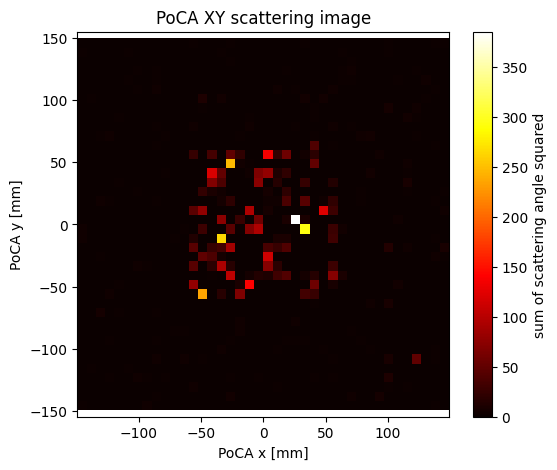

In [5]:
plt.figure(figsize=(6, 5))
plt.hist2d(df["poca_x_mm"], df["poca_y_mm"], bins=40, weights=df["theta_mrad"]**2, cmap="hot")
plt.colorbar(label="sum of scattering angle squared")
plt.xlabel("PoCA x [mm]"); plt.ylabel("PoCA y [mm]")
plt.title("PoCA XY scattering image")
plt.axis("equal"); plt.show()


## 5. 固定体素 PoCA 基线
将成像区域均匀划分为小立方体。每个体素累计其中 PoCA 点的散射角平方：$W_i = \sum_{j \in i} \theta_j^2$。

In [ ]:
def voxelize_poca(data, bins=30, xy_limit=150, z_limit=100):
    """Return fixed-voxel PoCA intensity and its bin edges. Units are mm and mrad.
    Events outside the imaging volume are excluded.
    """
    valid = data[(data["poca_x_mm"].abs() <= xy_limit) &
                 (data["poca_y_mm"].abs() <= xy_limit) &
                 (data["poca_z_mm"].abs() <= z_limit)]
    edges = [np.linspace(-xy_limit, xy_limit, bins + 1),
             np.linspace(-xy_limit, xy_limit, bins + 1),
             np.linspace(-z_limit, z_limit, bins + 1)]
    weights = valid["theta_mrad"].to_numpy() ** 2
    volume, edges = np.histogramdd(
        valid[["poca_x_mm", "poca_y_mm", "poca_z_mm"]].to_numpy(),
        bins=edges, weights=weights
    )
    return volume, edges, valid

voxel_volume, voxel_edges, valid_events = voxelize_poca(df)
print(f"events in imaging volume: {len(valid_events)} / {len(df)}")
print("voxel grid:", voxel_volume.shape)


## 6. 固定体素 PoCA 的 XY 投影
沿 z 方向累积体素强度，得到传统 PoCA 的二维散射图。

In [ ]:
xy_image = voxel_volume.sum(axis=2)
plt.figure(figsize=(6, 5))
plt.pcolormesh(voxel_edges[0], voxel_edges[1], xy_image.T, shading="auto", cmap="inferno")
plt.colorbar(label=r"$\sum \theta^2$ [mrad$^2$]")
plt.xlabel("PoCA x [mm]"); plt.ylabel("PoCA y [mm]")
plt.title("Fixed-voxel PoCA XY projection")
plt.axis("equal"); plt.show()


## 7. 低统计量对比
同一重建参数下，只改变参与重建的事件数；这将作为以后改进算法的公平基线。

In [ ]:
event_counts = [1000, 3000, 10000]
fig, axes = plt.subplots(1, len(event_counts), figsize=(14, 4), constrained_layout=True)
for ax, n_events in zip(axes, event_counts):
    subset = df.iloc[:min(n_events, len(df))]
    vol, edges, used = voxelize_poca(subset)
    image = vol.sum(axis=2)
    im = ax.pcolormesh(edges[0], edges[1], image.T, shading="auto", cmap="inferno")
    ax.set_title(f"{len(subset)} events\n{len(used)} in volume")
    ax.set_xlabel("x [mm]"); ax.set_aspect("equal")
axes[0].set_ylabel("y [mm]")
fig.colorbar(im, ax=axes, label=r"$\sum \theta^2$ [mrad$^2$]")
plt.show()
